- Transaction-level classification: You treat each row as an independent transaction and predict Is Laundering directly from that row's own features (amount, currency, payment format, timestamp, sender/receiver bank). This is the most standard supervised classification setup — one row in, one label out.
- Account/entity-level classification: You roll transactions up to the account level and predict whether an account is involved in laundering, based on aggregated behavior (transaction velocity, counterparty diversity, in/out amount ratios, etc.).
- Pattern/subgraph detection: You try to directly detect the structural typologies the dataset was built around — fan-out, fan-in, cycles, scatter-gather, gather-scatter, stacking — by treating the data as a transaction graph and looking for these shapes, either via engineered graph features feeding a classifier, or a graph neural network reasoning over the network directly.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import duckdb
import pandas as pd
import psutil
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

## Helper Functions

In [ ]:
#
def show_ram():
    ram = psutil.virtual_memory()

    print(
        f"Used: {ram.used / 1024**3:.2f} GB | "
        f"Available: {ram.available / 1024**3:.2f} GB"
    )

show_ram()

Used: 0.93 GB | Available: 11.46 GB


In [ ]:
# # Create Parquet from CSV to be ran once.
# # Connect to parquet file subsequently

# import duckdb

# transaction_csv_path = '/content/drive/MyDrive/Projects/Practice ML notebooks/AML_detection/dataset/HI-Small_Trans.csv'
# transaction_parquet_path = '/content/drive/MyDrive/Projects/Practice ML notebooks/AML_detection/dataset/HI-Small_Trans.parquet'
# account_csv_path = "/content/drive/MyDrive/Projects/Practice ML notebooks/AML_detection/dataset/HI-Small_accounts.csv"
# account_parquet_path = "/content/drive/MyDrive/Projects/Practice ML notebooks/AML_detection/dataset/HI-Small_accounts.parquet"

# con = duckdb.connect()

# duckdb.sql(f"""
#     COPY (SELECT
#                 ROW_NUMBER() OVER (ORDER BY Timestamp, Account, Account_1) AS transaction_id,
#                 Timestamp::TIMESTAMP                AS timestamp,
#                 "From Bank"::VARCHAR                AS sender_bank,
#                 Account::VARCHAR                    AS sender_account,
#                 "Amount Paid"::DOUBLE               AS sent_amount,
#                 "Payment Currency"::VARCHAR         AS sent_currency,
#                 "To Bank"::VARCHAR                  AS receiver_bank,
#                 Account_1::VARCHAR                  AS receiver_account,
#                 "Amount Received"::DOUBLE           AS received_amount,
#                 "Receiving Currency"::VARCHAR       AS receiving_currency,
#                 "Payment Format"::VARCHAR           AS payment_format,
#                 "Is Laundering"::BIGINT             AS is_laundering
#          FROM read_csv_auto('{transaction_csv_path}'))
#     TO '{transaction_parquet_path}' (FORMAT PARQUET)
# """)


# duckdb.sql(f"""
#     COPY (SELECT
#                 "Bank Name"::VARCHAR             AS bank_name,
#                 "Bank ID"::VARCHAR               AS bank_id,
#                 "Account Number"::VARCHAR        AS account_number,
#                 "Entity ID"::VARCHAR             AS entity_id,
#                 "Entity Name"::VARCHAR           AS entity_name
#              FROM read_csv_auto('{account_csv_path}'))
#     TO '{account_parquet_path}' (FORMAT PARQUET)
# """)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

## Load Dataset in Parquet Format into DuckDB

In [ ]:
import duckdb

In [ ]:
con = duckdb.connect()

In [ ]:
transaction_path = '/content/drive/MyDrive/Projects/Practice ML notebooks/AML_detection/dataset/HI-Small_Trans.parquet'
account_path = "/content/drive/MyDrive/Projects/Practice ML notebooks/AML_detection/dataset/HI-Small_accounts.parquet"

cleaned_transaction = '/content/drive/MyDrive/Projects/Practice ML notebooks/AML_detection/dataset/transaction_cleaned.parquet'

In [ ]:
trans_count = con.execute(f"""SELECT COUNT(*) FROM read_parquet('{transaction_path}')""").fetchall()[0][0]
acc_count = con.execute(f"""SELECT COUNT(*) FROM read_parquet('{account_path}')""").fetchall()[0][0]
print(f"Transaction Count: {trans_count:,}")
print(f"Account Count: {acc_count:,}")

Transaction Count: 5,078,345
Account Count: 518,581


In [ ]:
print(duckdb.sql(f"DESCRIBE SELECT * FROM read_parquet('{transaction_path}')").df())

              column_name column_type null   key default extra
0          transaction_id      BIGINT  YES  None    None  None
1   transaction_timestamp   TIMESTAMP  YES  None    None  None
2             sender_bank     VARCHAR  YES  None    None  None
3          sender_account     VARCHAR  YES  None    None  None
4             sent_amount      DOUBLE  YES  None    None  None
5           sent_currency     VARCHAR  YES  None    None  None
6           receiver_bank     VARCHAR  YES  None    None  None
7        receiver_account     VARCHAR  YES  None    None  None
8         received_amount      DOUBLE  YES  None    None  None
9      receiving_currency     VARCHAR  YES  None    None  None
10         payment_format     VARCHAR  YES  None    None  None
11          is_laundering      BIGINT  YES  None    None  None


In [ ]:
con.execute(f"""SELECT * FROM read_parquet('{transaction_path}') LIMIT 1 offset 1""").df()["transaction_timestamp"]

,transaction_timestamp
0,2022-09-01


In [ ]:
con.execute(f"""SELECT * FROM read_parquet('{account_path}') LIMIT 1""").df()

,bank_name,bank_id,account_number,entity_id,entity_name
0,Portugal Bank #4507,331579,80B779D80,80062E240,Sole Proprietorship #50438


In [ ]:
con.sql(f'SELECT sent_currency, count(*) as count FROM read_parquet("{transaction_path}") GROUP BY sent_currency order by count desc').show()

┌───────────────────┬─────────┐
│   sent_currency   │  count  │
│      varchar      │  int64  │
├───────────────────┼─────────┤
│ US Dollar         │ 1895172 │
│ Euro              │ 1168297 │
│ Swiss Franc       │  234860 │
│ Yuan              │  213752 │
│ Shekel            │  192184 │
│ Rupee             │  190202 │
│ UK Pound          │  180738 │
│ Yen               │  155209 │
│ Ruble             │  155178 │
│ Bitcoin           │  146066 │
│ Canadian Dollar   │  140042 │
│ Australian Dollar │  136769 │
│ Mexican Peso      │  110159 │
│ Saudi Riyal       │   89014 │
│ Brazil Real       │   70703 │
├───────────────────┴─────────┤
│ 15 rows           2 columns │
└─────────────────────────────┘



In [ ]:
con.sql(f"DESCRIBE SELECT * FROM read_parquet('{transaction_path}')").show()


┌────────────────────┬─────────────┬─────────┬─────────┬─────────┬─────────┐
│    column_name     │ column_type │  null   │   key   │ default │  extra  │
│      varchar       │   varchar   │ varchar │ varchar │ varchar │ varchar │
├────────────────────┼─────────────┼─────────┼─────────┼─────────┼─────────┤
│ timestamp          │ DATE        │ YES     │ NULL    │ NULL    │ NULL    │
│ sender_bank        │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ sender_account     │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ sent_amount        │ DOUBLE      │ YES     │ NULL    │ NULL    │ NULL    │
│ sent_currency      │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ receiver_bank      │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ receiver_account   │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ received_amount    │ DOUBLE      │ YES     │ NULL    │ NULL    │ NULL    │
│ receiving_currency │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │

In [ ]:
# Time period
con.execute(f"""SELECT min(timestamp), max(timestamp) FROM read_parquet('{transaction_path}')""").df()

,"min(""timestamp"")","max(""timestamp"")"
0,2022-09-01,2022-09-18


In [ ]:
# Bank details
result = con.execute(f"""SELECT COUNT(DISTINCT sender_bank) AS "Unique sender Banks",
                        COUNT(DISTINCT receiver_bank) AS "Unique reciever Banks"
             FROM read_parquet('{transaction_path}')""").df()

result.style.format("{:,.0f}")

,Unique sender Banks,Unique reciever Banks
0,"30,528","15,850"


In [ ]:
result1 = con.execute(f"""SELECT SUM(CASE WHEN sender_bank = receiver_bank THEN 1 ELSE 0 End) AS "Self-Transaction (Same Bank)"FROM read_parquet('{transaction_path}')""").fetchall()
result2 = con.execute(f"""SELECT SUM(CASE WHEN sender_bank != receiver_bank THEN 1 ELSE 0 End) AS "Self-Transaction (Same Bank)"FROM read_parquet('{transaction_path}')""").fetchall()

print(f"Self Transaction (same bank): {result1[0][0]:,} | Non-Self Transaction (different bank): {result2[0][0]:,}")


Self Transaction (same bank): 691,255 | Non-Self Transaction (different bank): 4,387,090


In [ ]:
##Check for missing values - transaction table

trans_columns = ["timestamp", "sender_bank", "sender_account", "sent_amount", "sent_currency", "receiver_bank", "receiver_account",
            "received_amount", "receiving_currency", "payment_format",	"is_laundering"]

select_clauses = [f"COUNT(*) - COUNT({col}) AS {col}" for col in trans_columns]
query = f"""
    SELECT {', '.join(select_clauses)}
    FROM read_parquet('{transaction_path}')
"""

missing_df = con.execute(query).df().T

print(missing_df)


                    0
timestamp           0
sender_bank         0
sender_account      0
sent_amount         0
sent_currency       0
receiver_bank       0
receiver_account    0
received_amount     0
receiving_currency  0
payment_format      0
is_laundering       0


In [ ]:
##check for missing values in account data
acc_columns = ["bank_name",	"bank_id",	"account_number", "entity_id",	"entity_name"]
select_clauses = [f"COUNT(*) - COUNT({col}) AS {col}" for col in acc_columns]
query = f"""
    SELECT {', '.join(select_clauses)}
    FROM read_parquet('{account_path}')
"""

missing_df = con.execute(query).df().T
print(missing_df)

                0
bank_name       0
bank_id         0
account_number  0
entity_id       0
entity_name     0


In [ ]:
# Check for duplicates - account table

all_trans_columns = ", ".join(trans_columns)

query = f"""
    SELECT {all_trans_columns}, COUNT(*)
    FROM read_parquet('{transaction_path}')
    GROUP BY {all_trans_columns}
    HAVING COUNT(*) > 1
"""

duplicates_df = con.execute(query).df()

if duplicates_df.empty:
    print("No exact duplicate rows found. Every row is unique!")
else:
    print(f"Found {len(duplicates_df)} unique rows that have duplicates:")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Found 9 unique rows that have duplicates:


In [ ]:
# Treating 9 duplicates found

partition_columns = ", ".join(trans_columns)

dedup_query = f"""
COPY (
    SELECT
        transaction_id,
        {partition_columns}
    FROM read_parquet('{transaction_path}')
    QUALIFY ROW_NUMBER() OVER (
        PARTITION BY {partition_columns}
        ORDER BY transaction_id ASC
    ) = 1
) TO '{cleaned_transaction}' (FORMAT 'PARQUET');
"""

print("Deduplicating and writing to a new file...")
con.execute(dedup_query)
print(f"Successfully created clean file at: {cleaned_transaction}")



Deduplicating and writing to a new file...


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Successfully created clean file at: /content/drive/MyDrive/Projects/Practice ML notebooks/AML_detection/dataset/transaction_cleaned.parquet


In [ ]:
raw_row_count = con.execute(f"""SELECT count(*) FROM read_parquet('{transaction_path}')""").fetchall()[0][0]
clean_row_count = con.execute(f"""SELECT count(*) FROM read_parquet('{cleaned_transaction}')""").fetchall()[0][0]

print(f"Count of rows in the raw transaction table: {raw_row_count:,}")
print(f"Count of rows in the cleaned transaction table: {clean_row_count:,}")

Count of rows in the raw transaction table: 5,078,345
Count of rows in the cleaned transaction table: 5,078,336


In [ ]:
all_acc_columns = ", ".join(acc_columns)

query = f"""
    SELECT {all_acc_columns}, COUNT(*)
    FROM read_parquet('{account_path}')
    GROUP BY {all_acc_columns}
    HAVING COUNT(*) > 1
"""

missing_acct_df = con.execute(query).df()
if missing_acct_df.empty:
    print("No duplicates in account table")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

No duplicates in account table


In [ ]:
# LABEL EXPLORATION
label_info = con.execute(f"""SELECT is_laundering, count(*) as count FROM read_parquet('{cleaned_transaction}') GROUP BY is_laundering""").df()
label_info["%_of_total"] = label_info["count"] / label_info["count"].sum()*100
label_info

,is_laundering,count,%_of_total
0,0,5073159,99.898057
1,1,5177,0.101943


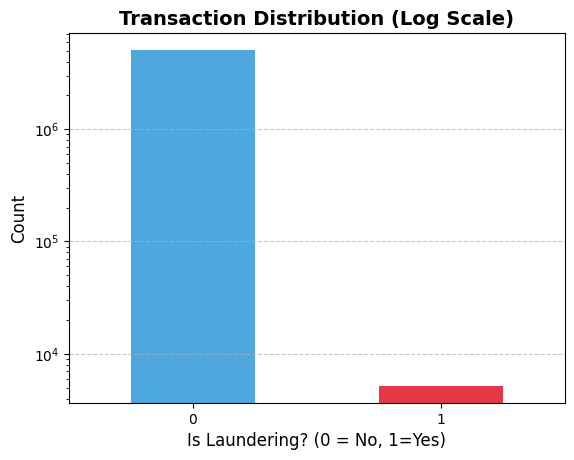

In [ ]:
ax = label_info.set_index("is_laundering")["count"].plot(
    kind="bar",
    logy=True,
    color=["#4ea8de", "#e63946"],
)

plt.title("Transaction Distribution (Log Scale)", fontsize=14, fontweight="bold")
plt.xlabel("Is Laundering? (0 = No, 1=Yes)", fontsize=12)
plt.ylabel("Count", fontsize=12)
plt.xticks(rotation=0)
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.show()

In [ ]:
# Label distribution over time

query = f"""
        SELECT
        CAST(timestamp AS DATE) AS date,
        SUM(CASE WHEN is_laundering = 0 THEN 1 ELSE 0 END) AS non_laundering_count,
        SUM(CASE WHEN is_laundering = 1 THEN 1 ELSE 0 END) AS laundering_count
        FROM read_parquet('{cleaned_transaction}')
        GROUP BY date
        ORDER BY date
"""

label_time_df = con.execute(query).df()
label_time_df

,date,non_laundering_count,laundering_count
0,2022-09-01,1114597.0,322.0
1,2022-09-02,754041.0,408.0
2,2022-09-03,206991.0,391.0
3,2022-09-04,207023.0,407.0
4,2022-09-05,482179.0,471.0
5,2022-09-06,481558.0,531.0
6,2022-09-07,482253.0,497.0
7,2022-09-08,482232.0,539.0
8,2022-09-09,653949.0,514.0
9,2022-09-10,207883.0,442.0


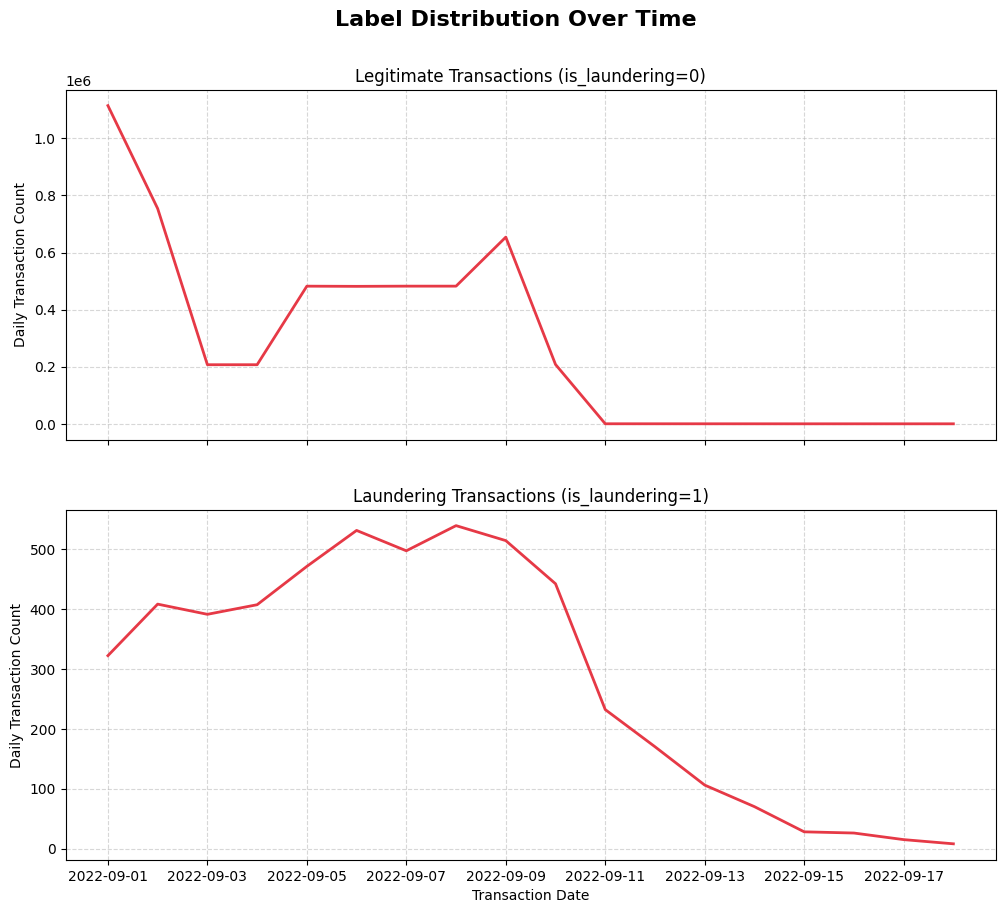

In [ ]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 10), sharex=True)

ax1.plot(label_time_df["date"], label_time_df["non_laundering_count"],  color="#e63946", linewidth=2 )
ax1.set_title("Legitimate Transactions (is_laundering=0)", fontsize=12)
ax1.set_ylabel("Daily Transaction Count")
ax1.grid(True, linestyle="--", alpha=0.5)

ax2.plot(label_time_df["date"], label_time_df["laundering_count"],  color="#e63946", linewidth=2 )
ax2.set_title("Laundering Transactions (is_laundering=1)", fontsize=12)
ax2.set_ylabel("Daily Transaction Count")
ax2.grid(True, linestyle="--", alpha=0.5)

plt.xlabel("Transaction Date")
plt.suptitle("Label Distribution Over Time", fontsize=16, fontweight="bold", y=0.96)
plt.tight_layout
plt.show()

In [ ]:
# THE TIME SERIES CLIFF

# The "background" legitimate traffic stream appears to have been simulated only for a fixed window (~Sept 1–10), then abruptly stops.
# Laundering transactions, by contrast, taper off gradually over the following week — likely because laundering scenarios are scripted as multi-step sequences (
# e.g. a fan-out pattern executing over several days) that were already "in motion" past where the normal-traffic generator cut off.

# With  random split, the model will likely look at any data past September 11th and automatically predict is_laundering=1 with 100% certainty
# simply because non_laundering_count is 0. It will learn a fake rule ("any transaction after Sept 11 is laundering") instead of learning behavioral patterns.

# The approach will be to:
# Not use data after 2022-09-11 for testing or training The data past this point is highly corrupted.
# to train the model strictly on a time window where both distributions are active (e.g., Train: Sept 1 to Sept 8, Test: Sept 9 to Sept 11).
# use time-based train/test split

In [ ]:
# Label distribution by categorical field

category_fields = ["sender_bank", "sent_currency", "receiver_bank", "receiving_currency", "payment_format"]
label_summaries = {}
for field in category_fields:
    query = f"""
    SELECT {field} AS field,
            COUNT(*) AS total_transactions,
            SUM(CASE WHEN is_laundering = 1 THEN 1 ELSE 0 END) AS laundering_count,
            (SUM(CASE WHEN is_laundering = 1 THEN 1 ELSE 0 END) / count(*)) AS pct_laundering
    FROM read_parquet('{cleaned_transaction}')
    GROUP BY {field}
    ORDER BY pct_laundering DESC
    LIMIT 20
    """
    label_summaries[field] = con.execute(query).df()

query = f"""
SELECT sender_bank,
        receiver_bank,
        COUNT(*) AS total_transactions,
        SUM(CASE WHEN is_laundering = 1 THEN 1 ELSE 0 END) AS laundering_count,
        (SUM(CASE WHEN is_laundering = 1 THEN 1 ELSE 0 END) *100/ count(*)) AS pct_laundering
FROM read_parquet('{cleaned_transaction}')
GROUP BY sender_bank, receiver_bank
--HAVING COUNT(*) >= 10
ORDER BY laundering_count DESC, total_transactions DESC, pct_laundering DESC
LIMIT 15
"""
bank_pair_df = con.execute(query).df()

In [ ]:
bank_pair_df

,sender_bank,receiver_bank,total_transactions,laundering_count,pct_laundering
0,015231,023691,31,27.0,87.096774
1,023691,015231,63,20.0,31.746032
2,0049365,0119,30,18.0,60.000000
3,0148350,0148350,257,16.0,6.225681
4,0119,0049365,72,15.0,20.833333
5,0148350,0050528,17,13.0,76.470588
6,020,022,961,11.0,1.144641
7,0119,0222,690,11.0,1.594203
8,0048309,0119,285,11.0,3.859649
9,0119,0048309,317,10.0,3.154574


Text(0.5, 0, 'Percentage of Transactions')

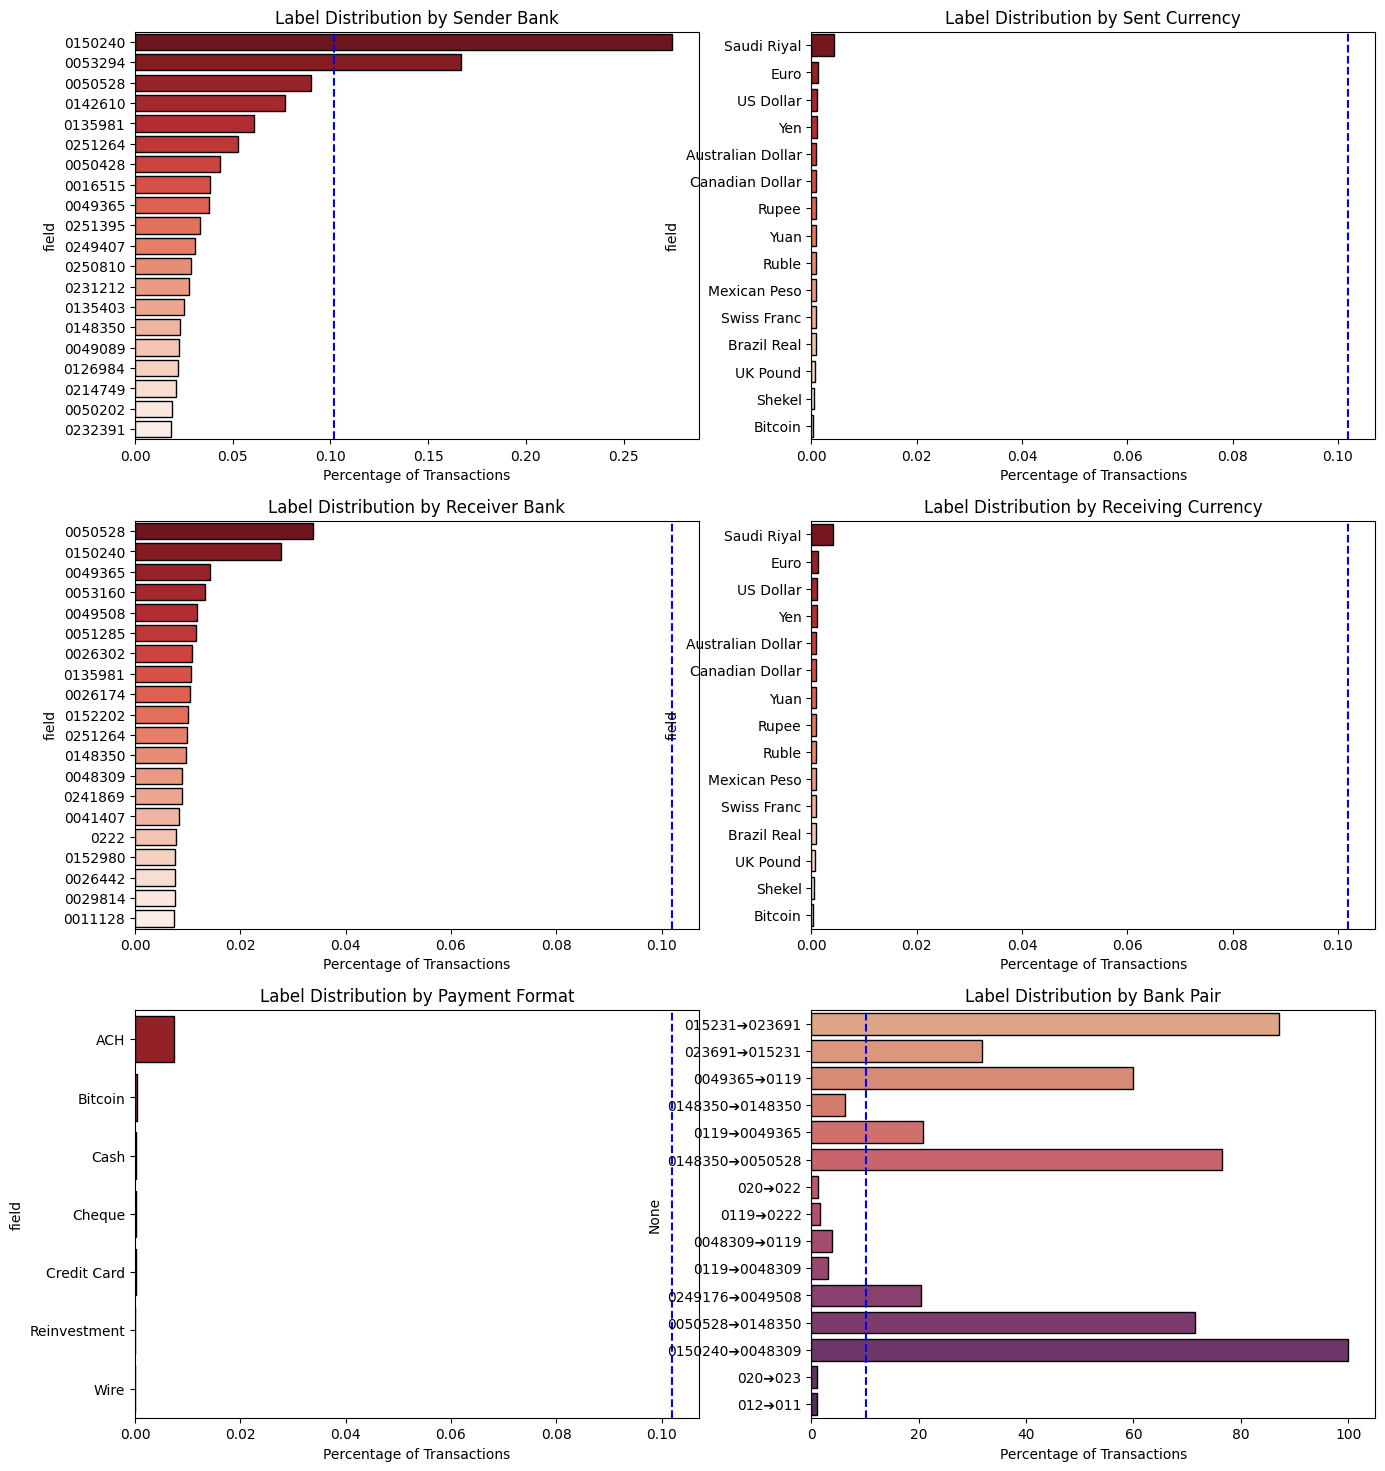

In [ ]:
fig, axes = plt.subplots(3, 2, figsize=(16, 18))
axes = axes.flatten()

for i, field in enumerate(category_fields):
    df = label_summaries[field]

    sns.barplot(data=df, x="pct_laundering", y="field", ax=axes[i], edgecolor="black", palette="Reds_r", hue="field")
    axes[i].axvline(x=0.101945, color="blue", linestyle="--", label="Global Base Rate (0.10%)")
    axes[i].set_title(f"Label Distribution by {field.replace("_", " ").title()}", fontsize=12)
    axes[i].set_xlabel("Percentage of Transactions")

sns.barplot(data=bank_pair_df, x="pct_laundering", y=bank_pair_df["sender_bank"] + "➔" + bank_pair_df["receiver_bank"],
            ax=axes[5], edgecolor="black", palette="flare", hue=bank_pair_df["sender_bank"] + "➔" + bank_pair_df["receiver_bank"])
axes[5].axvline(x=0.101945*100, color="blue", linestyle="--", label="Global Base Rate (0.10%)")
axes[5].set_title(f"Label Distribution by Bank Pair", fontsize=12)
axes[5].set_xlabel("Percentage of Transactions")

#### Further Explorations

In [ ]:
account_pair_query = f"""
    SELECT
        sender_bank,
        sender_account,
        receiver_bank,
        receiver_account,
        COUNT(*) AS total_transactions,
        SUM(CASE WHEN is_laundering = 1 THEN 1 ELSE 0 END) AS laundering_count,
        (SUM(CASE WHEN is_laundering = 1 THEN 1 ELSE 0 END) * 100.0 / COUNT(*)) AS pct_laundering
    FROM read_parquet('{cleaned_transaction}')
    GROUP BY sender_bank, sender_account, receiver_bank, receiver_account
    HAVING laundering_count > 1
    ORDER BY total_transactions DESC, pct_laundering DESC
    LIMIT 30;
"""

print("Auditing account-pair distribution...")
account_pairs_df = con.execute(account_pair_query).df()



Auditing account-pair distribution...


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

In [ ]:
account_pairs_df

,sender_bank,sender_account,receiver_bank,receiver_account,total_transactions,laundering_count,pct_laundering
0,015231,80266F880,015231,80266F880,34,2.0,5.882353
1,070,100428738,0111812,8046E1B30,32,2.0,6.250000
2,070,100428660,01362,800CEA850,30,2.0,6.666667
3,070,100428660,0053160,813908380,30,2.0,6.666667
4,070,100428660,0123102,80D2ACC90,30,2.0,6.666667
5,015231,80266F880,023691,8021353D0,28,27.0,96.428571
6,070,100428660,0028733,81108E620,21,2.0,9.523810
7,070,100428660,0219184,80C0D8D70,21,2.0,9.523810
8,023691,8021353D0,015231,80266F880,20,20.0,100.000000
9,070,100428A08,0248857,811D5F740,20,2.0,10.000000


In [ ]:
null_hypothesis_query = f"""
    WITH corridor_counts AS (
        SELECT
            sender_account,
            receiver_account,
            COUNT(*) AS total_transactions,
            SUM(CASE WHEN is_laundering = 1 THEN 1 ELSE 0 END) AS laundering_count
        FROM read_parquet('{cleaned_transaction}')
        GROUP BY sender_account, receiver_account
    )
    SELECT
        COUNT(*) AS total_corridors_in_range,
        SUM(CASE WHEN laundering_count = 0 THEN 1 ELSE 0 END) AS pure_legitimate_corridors,
        SUM(CASE WHEN laundering_count > 0 THEN 1 ELSE 0 END) AS contaminated_corridors
    FROM corridor_counts
    WHERE total_transactions BETWEEN 7 AND 35;
"""
print(con.execute(null_hypothesis_query).df())


   total_corridors_in_range  pure_legitimate_corridors  contaminated_corridors
0                    212236                   211653.0                   583.0


In [ ]:
footprint_query = f"""
    WITH total_universe AS (
        SELECT sender_account AS acct FROM read_parquet('{cleaned_transaction}')
        UNION
        SELECT receiver_account  AS acct FROM read_parquet('{cleaned_transaction}')
    ),
    laundering_universe AS (
        SELECT sender_account AS acct FROM read_parquet('{cleaned_transaction}') WHERE is_laundering = 1
        UNION
        SELECT receiver_account  AS acct FROM read_parquet('{cleaned_transaction}') WHERE is_laundering = 1
    )
    SELECT
        (SELECT COUNT(*) FROM total_universe) AS total_unique_accounts,
        (SELECT COUNT(*) FROM laundering_universe) AS unique_laundering_accounts,
        ((SELECT COUNT(*) FROM laundering_universe) * 100.0 / (SELECT COUNT(*) FROM total_universe)) AS footprint_pct;
"""
print(con.execute(footprint_query).df())


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

   total_unique_accounts  unique_laundering_accounts  footprint_pct
0                 515080                        6357       1.234177


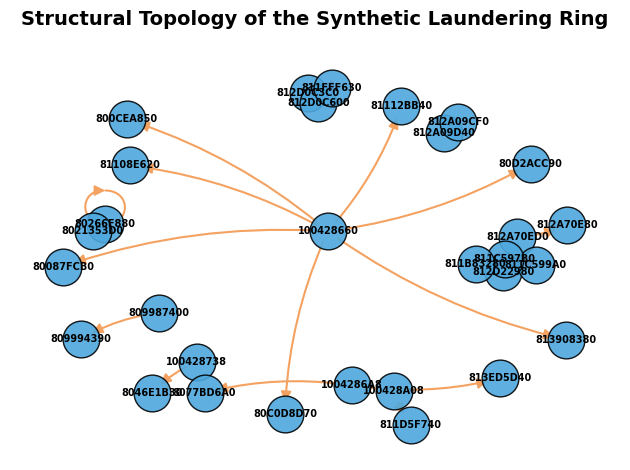

In [ ]:
import networkx as nx
import matplotlib.pyplot as plt

# 1. Filter for your active clusters from your previous dataframe
# We focus on the high-risk corridors to keep the plot clean and readable
graph_df = account_pairs_df[account_pairs_df["pct_laundering"] > 2.0]

# 2. Initialize Directed Graph
G = nx.DiGraph()

# 3. Add edges with weights and attributes
for _, row in graph_df.iterrows():
    G.add_edge(
        row["sender_account"],
        row["receiver_account"],
        weight=row["total_transactions"],
        pct=row["pct_laundering"]
    )

# 4. Set up visualization layouts and styles
plt.figsize=(14, 10)
pos = nx.spring_layout(G, k=0.5, seed=42) # k adjusts spacing between dense nodes

# Color edges dynamically: Red for 100% leak, Orange/Muted for mixed behavioral nodes
edge_colors = []
edge_widths = []
for u, v, data in G.edges(data=True):
    if data["pct"] == 100.0:
        edge_colors.append("#e63946") # Strong Leak Red
        edge_widths.append(3.0)
    else:
        edge_colors.append("#f4a261") # Structuring/Mixed Orange
        edge_widths.append(1.5)

# 5. Draw the graph assets
nx.draw_networkx_nodes(G, pos, node_size=700, node_color="#4ea8de", edgecolors="black", alpha=0.9)
nx.draw_networkx_labels(G, pos, font_size=7, font_weight="bold")
nx.draw_networkx_edges(G, pos, edge_color=edge_colors, width=edge_widths, arrowsize=15, connectionstyle="arc3,rad=0.1")

plt.title("Structural Topology of the Synthetic Laundering Ring", fontsize=14, fontweight="bold", pad=20)
plt.axis("off")
plt.tight_layout()
plt.show()


In [ ]:
# 1. The investigation showed that the baseline laundering rate across the dataset was extremely low,
# hovering at approximately 0.10% across most standard categorical fields.

# 2. Individual currencies (e.g., US Dollar, Euro, Yen) and payment formats (e.g., Cash, Wire, Credit Card) displayed
# virtually flat 0.00% laundering concentrations, with only minor blips visible in Saudi Riyal and ACH transactions.

# 3. The audit revealed severe, anomalous target leakage at the bank-pair level,
# where specific corridors (such as 0150240 ➔ 0048309) yielded a definitive 100% money laundering rate.

# 4. Deep-dive account tracking confirmed that this bank-level leakage was driven by an isolated "Account-Isolated Rule,"
# where exactly one dedicated account pair per corridor exclusively routed illicit funds.

# 5. Graph topology analysis exposed highly structured, scripted simulation artifacts, including a centralized "Hub & Fan"
# smurfing node (100428660) spraying funds outward, alongside completely detached, closed-loop layering rings (e.g., 812D0C3C0 and 811FFF630).

# 6. Statistical null-hypothesis testing validated that these contaminated structures were a deliberate simulation footprint,
# as 99.73% of all comparable low-volume corridors (7–35 transactions) in the dataset were completely clean.

# 7.Final footprint metrics established that only 1.23% of the entire 515,080 account universe ever interacted with a laundering transaction.

In [ ]:
# # Modeling Implications & Decisions

# Including raw string identifiers for sender_account, receiver_account, or target-encoded bank IDs would cause tree-based models
#  (like XGBoost or LightGBM) to trivially memorize the 1.23% malicious blacklist rather than learning transferable patterns.

# the pipeline will be split into two distinct modeling tracks to explicitly isolate identity leakage from authentic behavioral features.

# For Track A (Anonymized Behavioral Model), all bank and account IDs will be excluded
# forcing the classifier to rely strictly on agnostic transaction dynamics, such as amounts, velocity windows, currency changes, and payment types.

# For Track B (Graph Topology Model), raw identity fields will be replaced with structural network metrics,
# translating the visual anomalies into features like In-Degree/Out-Degree centrality ratios, PageRank scores, and closed-cycle flags.

In [ ]:
# Amount distribution

#min, p25, median, p75, p99, max

query = f"""SELECT sent_currency,
SUM(sent_amount) AS sum,
COUNT(*) AS count,
MIN(sent_amount) AS min,
AVG(sent_amount) AS mean,
PERCENTILE_CONT(0.25) WITHIN GROUP (ORDER BY sent_amount) AS p25,
PERCENTILE_CONT(0.5) WITHIN GROUP (ORDER BY sent_amount) AS median,
PERCENTILE_CONT(0.75) WITHIN GROUP (ORDER BY sent_amount) AS p75,
PERCENTILE_CONT(0.99) WITHIN GROUP (ORDER BY sent_amount) AS p99,
MAX(sent_amount) AS max
FROM read_parquet('{cleaned_transaction}')
GROUP BY sent_currency
ORDER BY sum DESC"""

amount_distr = con.execute(query).df()
amount_distr.style.format("{:,.2f}", subset=amount_distr.select_dtypes(include=['float64']).columns)

,sent_currency,sum,count,min,mean,p25,median,p75,p99,max
0,Rupee,"7,008,031,220,839.34",190202,0.01,"36,845,202.58","11,216.02","65,475.12","402,347.75","278,669,905.38","965,933,305,301.71"
1,Ruble,"6,701,431,087,719.14",155178,0.01,"43,185,445.67","12,369.47","70,070.46","434,210.73","316,428,945.04","626,035,501,453.45"
2,Yen,"6,366,561,829,331.76",155209,0.01,"41,019,282.58","16,122.38","95,949.86","584,710.92","351,303,688.50","1,046,302,363,293.48"
3,US Dollar,"695,819,564,558.97",1895143,0.01,"367,159.40",160.49,904.25,"5,305.57","3,120,249.51","16,620,608,535.74"
4,Mexican Peso,"656,440,081,973.27",110159,0.01,"5,959,023.61","3,451.14","18,922.55","109,781.73","52,784,966.21","30,893,133,697.47"
5,Yuan,"351,361,926,125.40",213752,0.01,"1,643,783.10","1,028.51","6,065.82","36,059.61","20,978,877.83","5,243,592,783.03"
6,Brazil Real,"309,943,602,492.61",70703,0.01,"4,383,740.47",917.86,"5,331.73","31,264.40","23,800,709.01","149,963,208,139.35"
7,Euro,"307,419,216,606.27",1168286,0.01,"263,136.95",133.51,747.37,"4,428.39","2,503,750.19","13,463,989,346.24"
8,Shekel,"189,379,822,979.30",192184,0.01,"985,408.89",566.52,"3,115.04","17,536.79","8,805,178.31","9,494,645,650.85"
9,Canadian Dollar,"80,959,662,100.84",140042,0.01,"578,109.87",210.89,"1,142.96","6,696.90","3,922,070.79","21,500,692,156.37"


In [ ]:
# Amount distribution

#min, p25, median, p75, p99, max

query = f"""SELECT receiving_currency,
SUM(received_amount) AS sum,
COUNT(*) AS count,
MIN(received_amount) AS min,
AVG(received_amount) AS mean,
PERCENTILE_CONT(0.25) WITHIN GROUP (ORDER BY received_amount) AS p25,
PERCENTILE_CONT(0.5) WITHIN GROUP (ORDER BY received_amount) AS median,
PERCENTILE_CONT(0.75) WITHIN GROUP (ORDER BY received_amount) AS p75,
PERCENTILE_CONT(0.99) WITHIN GROUP (ORDER BY received_amount) AS p99,
MAX(received_amount) AS max
FROM read_parquet('{cleaned_transaction}')
GROUP BY receiving_currency
ORDER BY sum DESC"""

amount_distr = con.execute(query).df()
amount_distr.style.format("{:,.2f}", subset=amount_distr.select_dtypes(include=['float64']).columns)

,receiving_currency,sum,count,min,mean,p25,median,p75,p99,max
0,Ruble,"10,589,498,309,436.01",157361,0.01,"67,294,299.79","12,710.94","74,091.44","478,799.09","451,107,866.32","626,035,501,453.45"
1,Rupee,"9,280,027,189,468.01",192065,0.01,"48,317,117.59","11,683.38","69,926.19","443,188.73","356,882,701.73","965,933,305,301.71"
2,Yen,"7,667,912,684,692.35",156319,0.01,"49,052,979.39","17,147.68","104,534.53","655,044.29","480,423,360.38","1,046,302,363,293.48"
3,Mexican Peso,"766,499,875,351.58",111030,0.01,"6,903,538.46","3,544.99","19,626.79","115,173.40","55,963,145.63","30,893,133,697.47"
4,US Dollar,"589,436,924,527.98",1879340,0.01,"313,640.39",157.95,884.04,"5,147.06","2,884,451.81","16,620,608,535.74"
5,Yuan,"355,448,549,429.77",206551,0.01,"1,720,875.47","1,116.57","6,742.78","39,644.93","22,976,104.12","5,243,592,783.03"
6,Brazil Real,"336,820,409,452.40",71544,0.01,"4,707,877.80",933.12,"5,439.89","32,072.14","26,866,992.97","149,963,208,139.35"
7,Euro,"302,495,780,396.54",1172017,0.01,"258,098.46",132.61,738.35,"4,373.07","2,445,203.58","13,463,989,346.24"
8,Shekel,"207,462,697,795.76",194988,0.01,"1,063,976.75",573.83,"3,159.03","17,827.87","9,008,397.71","9,494,645,650.85"
9,Canadian Dollar,"83,673,668,079.80",141357,0.01,"591,931.55",211.77,"1,143.93","6,716.03","3,981,064.05","21,500,692,156.37"


In [ ]:
# Currency and Target

query = f"""SELECT sent_currency,
SUM(CASE WHEN is_laundering = 1 THEN 1 ELSE 0 END) AS is_laundering_cnt,
COUNT(*) AS count,
ROUND((SUM(CASE WHEN is_laundering = 1 THEN 1 ELSE 0 END) * 100.0 / COUNT(*) ), 2) AS pct_laundering
FROM read_parquet('{cleaned_transaction}')
GROUP BY sent_currency
ORDER BY pct_laundering DESC, is_laundering_cnt DESC"""

currency_target = con.execute(query).df()
currency_target

,sent_currency,is_laundering_cnt,count,pct_laundering
0,Saudi Riyal,374.0,89014,0.42
1,Euro,1372.0,1168286,0.12
2,US Dollar,1912.0,1895143,0.10
3,Yen,155.0,155209,0.10
4,Yuan,184.0,213752,0.09
5,Rupee,167.0,190202,0.09
6,Ruble,133.0,155178,0.09
7,Canadian Dollar,128.0,140042,0.09
8,Australian Dollar,127.0,136769,0.09
9,Swiss Franc,193.0,234860,0.08


In [ ]:

query = f"""SELECT receiving_currency,
SUM(CASE WHEN is_laundering = 1 THEN 1 ELSE 0 END) AS is_laundering_cnt,
COUNT(*) AS count,
ROUND((SUM(CASE WHEN is_laundering = 1 THEN 1 ELSE 0 END) * 100.0 / COUNT(*) ), 2) AS pct_laundering
FROM read_parquet('{cleaned_transaction}')
GROUP BY receiving_currency
ORDER BY pct_laundering DESC, is_laundering_cnt DESC"""

currency_target = con.execute(query).df()
currency_target

,receiving_currency,is_laundering_cnt,count,pct_laundering
0,Saudi Riyal,374.0,89971,0.42
1,Euro,1372.0,1172017,0.12
2,US Dollar,1912.0,1879340,0.10
3,Yen,155.0,156319,0.10
4,Yuan,184.0,206551,0.09
5,Rupee,167.0,192065,0.09
6,Canadian Dollar,128.0,141357,0.09
7,Australian Dollar,127.0,138511,0.09
8,Swiss Franc,193.0,237884,0.08
9,Ruble,133.0,157361,0.08


In [ ]:
# Currency value counts, payment format value counts, bank ID cardinality

query = f"""
WITH unnested AS (
    SELECT sent_currency AS currency, sender_bank AS bank FROM read_parquet('{cleaned_transaction}')
    UNION ALL
    SELECT receiving_currency AS currency, receiver_bank AS bank FROM read_parquet('{cleaned_transaction}')
),
payment_cardinality AS (
    SELECT COUNT(DISTINCT payment_format) AS payment_format_cardinality FROM read_parquet('{cleaned_transaction}')
    )
SELECT
    COUNT(DISTINCT currency) AS total_unique_currencies,
    COUNT(DISTINCT bank)     AS total_unique_banks,
    payment_cardinality.payment_format_cardinality
FROM unnested
CROSS JOIN payment_cardinality
GROUP BY payment_cardinality.payment_format_cardinality
"""

combined_counts = con.execute(query).df()
combined_counts

,total_unique_currencies,total_unique_banks,payment_format_cardinality
0,15,30528,7


In [ ]:
con.execute(f"""SELECT count(bank_name) as total_unique_available_banks
            FROM read_parquet('{account_path}')""").df()

,total_unique_available_banks
0,518581


In [ ]:
# Timestamp granularity: Date level
con.execute(f"""SELECT timestamp
            FROM read_parquet('{cleaned_transaction}') LIMIT 20""").df()

,timestamp
0,2022-09-01
1,2022-09-01
2,2022-09-01
3,2022-09-01
4,2022-09-01
5,2022-09-01
6,2022-09-01
7,2022-09-01
8,2022-09-01
9,2022-09-01


In [ ]:
query = f"""
SELECT
    typeof(timestamp) AS data_type,
    timestamp
FROM read_parquet('{cleaned_transaction}')
LIMIT 5
"""

con.execute(query).df()

,data_type,timestamp
0,TIMESTAMP,2022-09-01
1,TIMESTAMP,2022-09-01
2,TIMESTAMP,2022-09-01
3,TIMESTAMP,2022-09-01
4,TIMESTAMP,2022-09-01


In [ ]:
# Amount distribution for laundering=1 vs. 0 (median/IQR side by side — this is one GROUP BY "Is Laundering" query with approx_quantile(), tiny result, easy boxplot after).
# Payment format / currency distribution conditional on label — does laundering skew toward wire transfers, specific currencies, cross-border pairs?
# Time-of-day / day-of-week pattern conditional on label — laundering transactions timed differently than normal activity is a classic signal.
# Same-currency vs. cross-currency transactions — is laundering disproportionately cross-currency (common in real AML typologies, layering across jurisdictions)?

In [ ]:
# Label Class conditional comparisons
# 1. Amount distribution
# 2. payment format distribution
# 3. currency distribution
# 4. time of the day
# 5. day of the week
# 6. same currency
# 7. cross currency
print(trans_columns)

['timestamp', 'sender_bank', 'sender_account', 'sent_amount', 'sent_currency', 'receiver_bank', 'receiver_account', 'received_amount', 'receiving_currency', 'payment_format', 'is_laundering']


In [ ]:
# same currency (paid and received should be the same)
# check currency exchange combinations
# imply exchange rate (it should be consistent)
print("Same and cross currency distribution")
query = f"""
SELECT SUM(CASE WHEN sent_currency = receiving_currency THEN 1 ELSE 0 END) AS same_currency,
        SUM(CASE WHEN sent_currency != receiving_currency THEN 1 ELSE 0 END) AS cross_currency,
        COUNT(*) AS total_transactions
FROM read_parquet('{cleaned_transaction}')
"""

con.execute(query).df()


Same and cross currency distribution


,same_currency,cross_currency,total_transactions
0,5006170.0,72166.0,5078336


In [ ]:
# same currency (paid and received should be the same)
print("Validate Same amount for same currenct transactions.")
query = f"""
with same_currency as (
SELECT * FROM read_parquet('{cleaned_transaction}')
WHERE sent_currency = receiving_currency
)
SELECT
SUM(CASE WHEN sent_amount = received_amount THEN 1 ELSE 0 END) AS same_amount,
SUM(CASE WHEN sent_amount != received_amount THEN 1 ELSE 0 END) AS different_amount,
count(*) AS total_same_currency_txns
FROM same_currency
"""

con.execute(query).df()


Validate Same amount for same currenct transactions.


,same_amount,different_amount,total_same_currency_txns
0,5006170.0,0.0,5006170


In [ ]:
con.execute(f"""SELECT COUNT(DISTINCT receiving_currency) as currency_count FROM read_parquet('{cleaned_transaction}')""").df()

,currency_count
0,15


In [ ]:
# check currency exchange combinations
query = f"""
WITH fx_rates AS (
    SELECT
        sent_currency,
        receiving_currency,
        MEDIAN(received_amount / sent_amount) AS implicit_fx_rate,
        COUNT(*) AS total_transaction_count
    FROM read_parquet('{cleaned_transaction}')
    WHERE sent_currency != receiving_currency
      AND sent_amount > 0
      AND sent_currency = 'US Dollar'
    GROUP BY sent_currency, receiving_currency
),
transactions_in_usd AS (
SELECT t.sent_currency,
        t.receiving_currency,
        cASE WHEN t.sent_currency = 'US DOllar' THEN t.sent_amount
            ELSE t.sent_amount / fx_sent.implicit_fx_rate
        END AS sent_amount_usd,
        CASE WHEN t.receiving_currency = 'US Dollar' THEN t.received_amount
            ELSE t.received_amount / fx_rec.implicit_fx_rate
        END AS received_amount_usd,
        t.sent_amount,
        t.received_amount,
        t.timestamp,
        t.is_laundering
         FROM read_parquet('{cleaned_transaction}') as t
         LEFT JOIN fx_rates AS fx_sent
            ON t.sent_currency = fx_sent.sent_currency
        LEFT JOIN fx_rates AS fx_rec
            ON t.receiving_currency = fx_rec.receiving_currency
),
    quantiles AS (
    -- Compute the 25th, 50th (Median), and 75th percentiles per laundering flag
    SELECT
        is_laundering,
        approx_quantile(sent_amount_usd, 0.25) AS q25,
        approx_quantile(sent_amount_usd, 0.50) AS median_amount_usd,
        approx_quantile(sent_amount_usd, 0.75) AS q75,
        COUNT(*) AS total_transactions
    FROM transactions_in_usd
    GROUP BY is_laundering
)
SELECT
    is_laundering,
    total_transactions,
    q25 AS lower_quartile_usd,
    median_amount_usd,
    q75 AS upper_quartile_usd,
    (q75 - q25) AS iqr_usd
FROM quantiles;
"""


df_laundering_dist = con.execute(query).df()
df_laundering_dist

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,is_laundering,total_transactions,lower_quartile_usd,median_amount_usd,upper_quartile_usd,iqr_usd
0,0,29685500,23.580731,237.074203,2952.862712,2929.281981
1,1,30033,186.437587,1513.250223,7167.143588,6980.706001


In [ ]:
# Same-currency vs. cross-currency transactions

query = f"""
with same_currency as (
SELECT * FROM read_parquet('{cleaned_transaction}')
WHERE sent_currency = receiving_currency
),
cross_currency as (
SELECT * FROM read_parquet('{cleaned_transaction}')
WHERE sent_currency != receiving_currency
)
SELECT
    is_laundering,
    'Same Currency' AS currency_type,
    COUNT(*) AS total_transactions
    FROM same_currency
    GROUP BY is_laundering
UNION ALL
SELECT
    is_laundering,
    'Cross Currency' AS currency_type,
    COUNT(*) AS total_transactions
    FROM cross_currency
    GROUP BY is_laundering
"""

con.execute(query).df()


,is_laundering,currency_type,total_transactions
0,0,Same Currency,5000993
1,1,Same Currency,5177
2,0,Cross Currency,72166


In [ ]:
# All laundering cases are same currencies
print("Laundering cases for same currency and cross currency transactions:")
con.execute(f"""
SELECT
ANY_VALUE(is_laundering) as is_laundering,
SUM(CASE WHEN sent_currency != receiving_currency THEN 1 ELSE 0 END) AS cross_currency,
SUM(CASE WHEN sent_currency = receiving_currency THEN 1 ELSE 0 END) AS same_currency,
COUNT(*) AS total_transactions
FROM read_parquet('{cleaned_transaction}')
WHERE is_laundering = 1
""").df()

Laundering cases for same currency and cross currency transactions


,is_laundering,cross_currency,same_currency,total_transactions
0,1,0.0,5177.0,5177


In [ ]:
# All laundering transactions are same currency

In [ ]:
# Time-of-day / day-of-week pattern conditional on label
query = f"""
SELECT
    is_laundering,

    -- 1. Day of Week Options
    EXTRACT(DAYOFWEEK FROM timestamp) AS day_of_week_num,    -- 0 (Sunday) to 6 (Saturday)
    STRFTIME(timestamp, '%A') AS day_of_week_name,          -- 'Sunday', 'Monday', etc.

    -- 2. Time of Day Options
    EXTRACT(HOUR FROM timestamp) AS hour_of_day,            -- 0 to 23
    CASE
        WHEN EXTRACT(HOUR FROM timestamp) BETWEEN 0 AND 5 THEN 'Night'
        WHEN EXTRACT(HOUR FROM timestamp) BETWEEN 6 AND 11 THEN 'Morning'
        WHEN EXTRACT(HOUR FROM timestamp) BETWEEN 12 AND 17 THEN 'Afternoon'
        ELSE 'Evening'
    END AS time_of_day_bucket,

    COUNT(*) AS total_transactions

FROM read_parquet('{cleaned_transaction}')
GROUP BY is_laundering, day_of_week_num, day_of_week_name, hour_of_day, time_of_day_bucket
ORDER BY day_of_week_num, hour_of_day, is_laundering
"""

df_time = con.execute(query).df()
df_time.head(1)


,is_laundering,day_of_week_num,day_of_week_name,hour_of_day,time_of_day_bucket,total_transactions
0,0,0,Sunday,0,Night,22712


In [ ]:
df_time.groupby(["day_of_week_name", "is_laundering"])["total_transactions"].sum().unstack()#.plot(kind="bar", stacked=True)

is_laundering,0,1
day_of_week_name,,
Friday,1408010,948
Monday,482290,641
Saturday,414882,848
Sunday,207190,647
Thursday,1596847,889
Tuesday,481636,637
Wednesday,482304,567


In [ ]:
df_time.groupby(["hour_of_day", "is_laundering"])["total_transactions"].sum().unstack()

is_laundering,0,1
hour_of_day,,
0,634550,176
1,193576,152
2,192978,165
3,193103,146
4,193012,154
5,193712,188
6,194249,207
7,193141,195
8,192663,258


<Axes: xlabel='hour_of_day'>

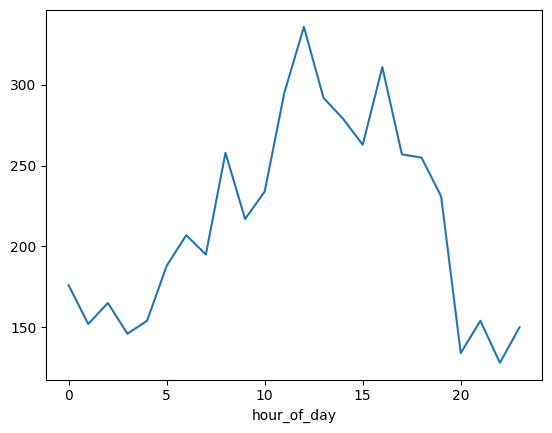

In [ ]:
df_time.groupby(["hour_of_day", "is_laundering"])["total_transactions"].sum().unstack()[1].plot(kind="line", stacked=True)

In [ ]:
df_time.groupby(["time_of_day_bucket", "is_laundering"])["total_transactions"].sum().unstack()#.plot(kind="bar", stacked=True)

is_laundering,0,1
time_of_day_bucket,,
Afternoon,1157972,1738
Evening,1155270,1052
Morning,1158986,1406
Night,1600931,981


In [ ]:
# Verify account identity
# is account_id alone is globally unique or whether you need the composite (bank_id, account_id) as the true identity key?
query = f"""
SELECT
 COUNT(DISTINCT receiver_account) as total_unique_accounts,
 COUNT(DISTINCT receiver_bank || '-' || receiver_account) as total_unique_bank_account_pairs
FROM read_parquet('{cleaned_transaction}')
"""

con.execute(query).df()


,total_unique_accounts,total_unique_bank_account_pairs
0,496995,496999


In [ ]:
# check mismatch rows on the sender's side

query = f"""
SELECT
    sender_account,
    COUNT(DISTINCT sender_bank) AS total_banks,
    LIST(DISTINCT sender_bank) AS associated_banks
FROM read_parquet('{cleaned_transaction}')
GROUP BY sender_account
HAVING COUNT(DISTINCT sender_bank) > 1
ORDER BY total_banks DESC
"""

df_mismatch = con.execute(query).df()
print(df_mismatch)


  sender_account  total_banks    associated_banks
0      8135B8250            2   [0221731, 027444]
1      80FA55EF0            2   [0138832, 013858]
2      80A7FD400            2  [0027755, 0028248]
3      81211BC00            2    [0142574, 01490]


In [ ]:
# check mismatch rows on the receiver's side
query = f"""
SELECT
    receiver_account,
    COUNT(DISTINCT receiver_bank) AS total_banks,
    LIST(DISTINCT receiver_bank) AS associated_banks
FROM read_parquet('{cleaned_transaction}')
GROUP BY receiver_account
HAVING COUNT(DISTINCT receiver_bank) > 1
ORDER BY total_banks DESC
"""

df_mismatch = con.execute(query).df()
print(df_mismatch)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

  receiver_account  total_banks    associated_banks
0        80FA56340            2   [013858, 0138832]
1        81211BA20            2    [0142574, 01490]
2        80A7FDE00            2  [0028248, 0027755]
3        8135B8200            2   [027444, 0221731]


In [ ]:
# build_account_activity(transactions) -> account_table:
#   outbound = GROUP BY sender_account:
#       out_txn_count = COUNT(*)
#       out_degree = COUNT(DISTINCT receiver_account)
#       out_laundering_count = SUM(is_laundering)

#   inbound = GROUP BY receiver_account:
#       in_txn_count = COUNT(*)
#       in_degree = COUNT(DISTINCT sender_account)
#       in_laundering_count = SUM(is_laundering)

#   FULL OUTER JOIN outbound, inbound ON account_id
#   -- FULL OUTER matters: an account that only ever sends (never receives)
#   -- would be silently dropped by an INNER JOIN

In [ ]:
# Build one unified account-activity table

query = f"""
WITH outbound AS (
    SELECT
        sender_bank || '-' || sender_account as sender_id,
        COUNT(*) AS out_txn_count,
        COUNT(DISTINCT receiver_account) AS out_degree,
        SUM(is_laundering) AS out_laundering_count
    FROM read_parquet('{cleaned_transaction}')
    GROUP BY sender_id
    ),
    inbound AS (
    SELECT
        receiver_bank || '-' || receiver_account as receiver_id,
        COUNT(*) AS in_txn_count,
        COUNT(DISTINCT sender_account) AS in_degree,
        SUM(is_laundering) AS in_laundering_count
    FROM read_parquet('{cleaned_transaction}')
    GROUP BY receiver_id
    ),

account_table as (SELECT
    -- Master ID column that catches accounts regardless of which side they appear on
    COALESCE(o.sender_id, i.receiver_id) AS account_id,

    -- Outbound metrics (default to 0 if the account only receives money)
    COALESCE(o.out_txn_count, 0) AS out_txn_count,
    COALESCE(o.out_degree, 0) AS out_degree,
    COALESCE(o.out_laundering_count, 0) AS out_laundering_count,

    -- Inbound metrics (default to 0 if the account only sends money)
    COALESCE(i.in_txn_count, 0) AS in_txn_count,
    COALESCE(i.in_degree, 0) AS in_degree,
    COALESCE(i.in_laundering_count, 0) AS in_laundering_count,

    -- Total combined traffic metrics
    COALESCE(o.out_txn_count, 0) + COALESCE(i.in_txn_count, 0) AS total_txn_count,
    COALESCE(o.out_laundering_count, 0) + COALESCE(i.in_laundering_count, 0) AS total_laundering_count

FROM outbound o
FULL OUTER JOIN inbound i
    ON o.sender_id = i.receiver_id
)
SELECT *,
        in_degree + out_degree AS total_degree,
        total_laundering_count / total_txn_count AS laundering_rate
FROM account_table

"""

df_account_activity = con.execute(query).df()
df_account_activity

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Buffered data was truncated after reaching the output size limit.

In [ ]:
# Quantify ring size

query = f"""
WITH all_accounts AS (
    -- Step 1: Capture the entire universe of unique accounts in the system
    SELECT sender_bank || '-' || sender_account AS account_id, is_laundering FROM read_parquet('{cleaned_transaction}')
    UNION ALL
    SELECT receiver_bank || '-' || receiver_account AS account_id, is_laundering FROM read_parquet('{cleaned_transaction}')
),

account_flags AS (
    -- Step 2: Determine if an account ever touched a laundering transaction
    SELECT
        account_id,
        MAX(is_laundering) AS ever_laundered
    FROM all_accounts
    GROUP BY account_id
)

-- Step 3: Compute the raw ring size and its scale vs. the entire universe
SELECT
    SUM(ever_laundered) AS laundering_ring_size,
    COUNT(*) AS total_account_universe,
    (CAST(SUM(ever_laundered) AS DOUBLE) / COUNT(*)) * 100 AS ring_size_percentage
FROM account_flags
"""

df_ring_size = con.execute(query).df()
print(df_ring_size)


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

   laundering_ring_size  total_account_universe  ring_size_percentage
0                6357.0                  515088              1.234158


In [ ]:
# Separate hubs from rings using the two metrics together
query = f"""
WITH outbound AS (
    SELECT
        sender_bank,
        sender_account,
        COUNT(*) AS out_txn_count,
        COUNT(DISTINCT receiver_account) AS out_degree,
        SUM(is_laundering) AS out_laundering_count
    FROM read_parquet('{cleaned_transaction}')
    GROUP BY sender_bank, sender_account
),
inbound AS (
    SELECT
        receiver_bank,
        receiver_account,
        COUNT(*) AS in_txn_count,
        COUNT(DISTINCT sender_account) AS in_degree,
        SUM(is_laundering) AS in_laundering_count
    FROM read_parquet('{cleaned_transaction}')
    GROUP BY receiver_bank, receiver_account
),
account_metrics AS (
    SELECT
        COALESCE(o.out_degree, 0) + COALESCE(i.in_degree, 0) AS total_degree,
        COALESCE(o.out_txn_count, 0) + COALESCE(i.in_txn_count, 0) AS total_txn_count,
        COALESCE(o.out_laundering_count, 0) + COALESCE(i.in_laundering_count, 0) AS total_laundering_count
    FROM outbound o
    FULL OUTER JOIN inbound i
        ON o.sender_bank = i.receiver_bank
       AND o.sender_account = i.receiver_account
)
SELECT
    total_degree,
    CASE
        WHEN total_txn_count > 0 THEN CAST(total_laundering_count AS DOUBLE) / total_txn_count
        ELSE 0.0
    END AS laundering_rate
FROM account_metrics
WHERE total_degree > 0 -- Exclude completely inactive structural artifacts
"""

df_scatter = con.execute(query).df()


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

In [ ]:
df_scatter.head(5)

,total_degree,laundering_rate
0,22,0.038462
1,16,0.000000
2,11,0.000000
3,18,0.000000
4,15,0.000000


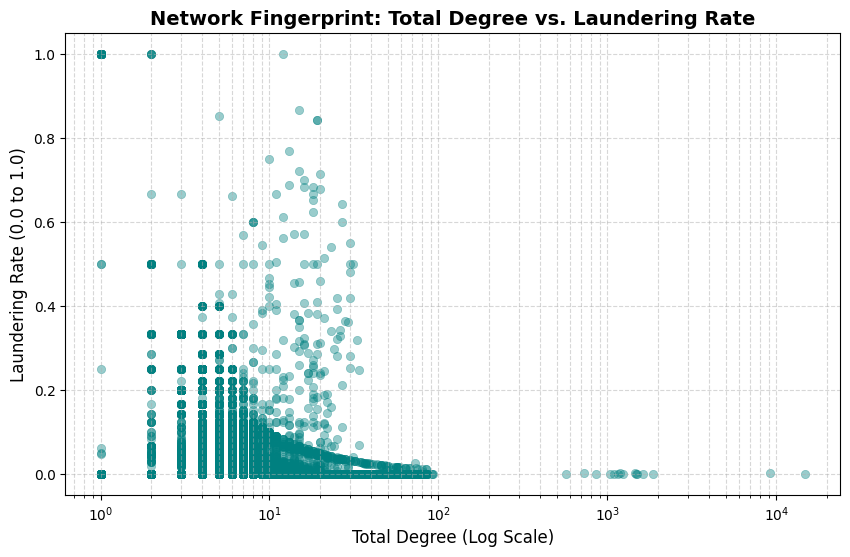

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

# Fixed 'colorCode' to 'color' to fix the AttributeError
sns.scatterplot(
    data=df_scatter,
    x='total_degree',
    y='laundering_rate',
    alpha=0.4,
    color='teal',       # <-- Fixed here
    edgecolor=None
)

# Apply log scale to the x-axis due to extreme degree skew
plt.xscale('log')

plt.title('Network Fingerprint: Total Degree vs. Laundering Rate', fontsize=14, fontweight='bold')
plt.xlabel('Total Degree (Log Scale)', fontsize=12)
plt.ylabel('Laundering Rate (0.0 to 1.0)', fontsize=12)
plt.grid(True, which="both", ls="--", alpha=0.5)

plt.show()


In [ ]:
query = f"""
WITH outbound AS (
    SELECT
        sender_bank, sender_account,
        COUNT(*) AS out_txn_count,
        COUNT(DISTINCT receiver_account) AS out_degree,
        SUM(is_laundering) AS out_laundering_count
    FROM read_parquet('{cleaned_transaction}')
    GROUP BY sender_bank, sender_account
),
inbound AS (
    SELECT
        receiver_bank, receiver_account,
        COUNT(*) AS in_txn_count,
        COUNT(DISTINCT sender_account) AS in_degree,
        SUM(is_laundering) AS in_laundering_count
    FROM read_parquet('{cleaned_transaction}')
    GROUP BY receiver_bank, receiver_account
),
account_table AS (
    SELECT
        COALESCE(o.sender_bank, i.receiver_bank) AS bank_id,
        COALESCE(o.sender_account, i.receiver_account) AS account_num,
        COALESCE(o.out_txn_count, 0) AS out_txn_count,
        COALESCE(o.out_degree, 0) AS out_degree,
        COALESCE(i.in_txn_count, 0) AS in_txn_count,
        COALESCE(i.in_degree, 0) AS in_degree,
        COALESCE(o.out_txn_count, 0) + COALESCE(i.in_txn_count, 0) AS total_txn_count,
        COALESCE(o.out_laundering_count, 0) + COALESCE(i.in_laundering_count, 0) AS total_laundering_count
    FROM outbound o
    FULL OUTER JOIN inbound i
        ON o.sender_bank = i.receiver_bank
       AND o.sender_account = i.receiver_account
)
SELECT
    bank_id || '-' || account_num AS account_id,
    total_txn_count,
    (out_degree + in_degree) AS total_degree,
    total_laundering_count,
    CASE
        WHEN total_txn_count > 0 THEN (CAST(total_laundering_count AS DOUBLE) / total_txn_count) * 100
        ELSE 0.0
    END AS laundering_rate_pct
FROM account_table
WHERE account_num IN ('100428660', '0148350', '0150240', '0048309')
ORDER BY laundering_rate_pct DESC;
"""

df_validation = con.execute(query).df()
df_validation


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,account_id,total_txn_count,total_degree,total_laundering_count,laundering_rate_pct
0,070-100428660,169756,14775,243.0,0.143147


In [ ]:
import networkx as nx
import pandas as pd

# 1. Extract the laundering sub-graph edges from DuckDB
edge_query = f"""
SELECT
    sender_bank || '-' || sender_account AS source,
    receiver_bank || '-' || receiver_account AS target
FROM read_parquet('{cleaned_transaction}')
WHERE is_laundering = 1
"""
df_edges = con.execute(edge_query).df()

# 2. Build an undirected graph out of the laundering network pathways
G = nx.from_pandas_edgelist(df_edges, source='source', target='target')

# 3. Calculate all isolated connected sub-networks (components)
components = list(nx.connected_components(G))

# 4. Map each account to its respective component size
component_data = []
for comp in components:
    comp_size = len(comp)
    for account in comp:
        component_data.append({'account_id': account, 'component_size': comp_size})

df_components = pd.DataFrame(component_data)

# 5. Merge component sizes back against your validation targets to verify isolation
df_validation_with_components = df_validation.merge(df_components, on='account_id', how='left')
df_validation_with_components


,account_id,total_txn_count,total_degree,total_laundering_count,laundering_rate_pct,component_size
0,070-100428660,169756,14775,243.0,0.143147,241


In [ ]:
import networkx as nx
import pandas as pd

print("🚀 Step 1/3: Extracting full edge universe from DuckDB...")
# Pull ALL edges using the complete transaction backbone (no filters)
edge_query = f"""
SELECT DISTINCT
    sender_bank || '-' || sender_account AS source,
    receiver_bank || '-' || receiver_account AS target
FROM read_parquet('{cleaned_transaction}')
"""
df_all_edges = con.execute(edge_query).df()

print("🕸️ Step 2/3: Building undirected network graph topology...")
# Construct the complete undirected network
G_full = nx.from_pandas_edgelist(df_all_edges, source='source', target='target')

print("🧮 Step 3/3: Running connected component sizing...")
# Find true connected components across the entire system
full_components = list(nx.connected_components(G_full))

# Map every unique account ID to its absolute component size
component_mapping = []
for comp in full_components:
    size_of_comp = len(comp)
    for node in comp:
        component_mapping.append({'account_id': node, 'true_component_size': size_of_comp})

df_true_components = pd.DataFrame(component_mapping)
print("✅ Component calculation complete!")


🚀 Step 1/3: Extracting full edge universe from DuckDB...


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

🕸️ Step 2/3: Building undirected network graph topology...
🧮 Step 3/3: Running connected component sizing...
✅ Component calculation complete!


In [ ]:
# Register our clean component dataframe as a temporary view inside DuckDB
con.register('temp_component_features', df_true_components)

final_features_query = f"""
WITH outbound AS (
    SELECT
        sender_bank, sender_account,
        COUNT(*) AS out_txn_count,
        COUNT(DISTINCT receiver_account) AS out_degree,
        SUM(is_laundering) AS out_laundering_count
    FROM read_parquet('{cleaned_transaction}')
    GROUP BY sender_bank, sender_account
),
inbound AS (
    SELECT
        receiver_bank, receiver_account,
        COUNT(*) AS in_txn_count,
        COUNT(DISTINCT sender_account) AS in_degree,
        SUM(is_laundering) AS in_laundering_count
    FROM read_parquet('{cleaned_transaction}')
    GROUP BY receiver_bank, receiver_account
),
account_metrics AS (
    SELECT
        COALESCE(o.sender_bank, i.receiver_bank) || '-' || COALESCE(o.sender_account, i.receiver_account) AS account_id,
        COALESCE(o.out_degree, 0) + COALESCE(i.in_degree, 0) AS total_degree,
        COALESCE(o.out_txn_count, 0) + COALESCE(i.in_txn_count, 0) AS total_txn_count,
        COALESCE(o.out_laundering_count, 0) + COALESCE(i.in_laundering_count, 0) AS total_laundering_count
    FROM outbound o
    FULL OUTER JOIN inbound i
        ON o.sender_bank = i.receiver_bank
       AND o.sender_account = i.receiver_account
),
base_rates AS (
    SELECT
        *,
        CASE
            WHEN total_txn_count > 0 THEN CAST(total_laundering_count AS DOUBLE) / total_txn_count
            ELSE 0.0
        END AS laundering_rate
    FROM account_metrics
)

-- Join everything with the true component mapping table
SELECT
    b.account_id,
    b.total_degree,
    b.total_txn_count,
    b.laundering_rate,
    c.true_component_size,
    CASE
        WHEN b.total_degree >= 500 AND b.laundering_rate <= 0.01 THEN 'hub'
        WHEN b.total_degree <= 35 AND b.laundering_rate >= 0.40 THEN 'ring_member'
        ELSE 'ordinary'
    END AS structural_role
FROM base_rates b
LEFT JOIN temp_component_features c ON b.account_id = c.account_id
"""

df_final_features = con.execute(final_features_query).df()


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

In [ ]:
# Sanity Check 1: Verify the Hub Account now reflects the Giant Connected Component
hub_check = df_final_features[df_final_features['account_id'].str.contains('100428660')]
print("\n--- 🏢 HUB ACCOUNT SANITY CHECK ---")
print(hub_check[['account_id', 'total_degree', 'true_component_size', 'structural_role']])

# Sanity Check 2: Verify a known Ring Account is truly structurally isolated
ring_check = df_final_features[df_final_features['account_id'].str.contains('0148350')].head(1)
print("\n--- 🕸️ RING ACCOUNT SANITY CHECK ---")
print(ring_check[['account_id', 'total_degree', 'true_component_size', 'structural_role']])



--- 🏢 HUB ACCOUNT SANITY CHECK ---
         account_id  total_degree  true_component_size structural_role
2045  070-100428660         14775               372089             hub

--- 🕸️ RING ACCOUNT SANITY CHECK ---
              account_id  total_degree  true_component_size structural_role
52719  0148350-811FB92D0             5               372089        ordinary


#### Feature Engineering

In [ ]:
# 1. Amount features: amount_usd, amount_zscore , log_amount_usd, is_round_number, amount_percentile_bucket
# 2. Currency / cross-border features: is_cross_currency, currency_risk_score, implied_fx_rate
# 3. Temporal features: day_of_week, is_weekend, hour_of_day, time_of_day_bucket, hour_risk_score, day_risk_score
# 4. Categorical encodings: payment_format(one_hot encoding), sender_bank / receiver_bank (frequency or target encoding)
# 5. Account velocity features (lookback window, as-of each transaction's timestamp: txn_count_last_24h, txn_count_last_7d,
                                                                # distinct_counterparties_last_7d, amount_zscore_vs_own_history

In [ ]:
query = f"""
    SELECT
        sent_currency as standard_currency,
        receiving_currency as exchange_currency,
        MEDIAN(received_amount / sent_amount) AS implicit_fx_rate,
        COUNT(*) AS total_transaction_count
    FROM read_parquet('{cleaned_transaction}')
    WHERE sent_amount > 0
      AND sent_currency = 'US Dollar'
    GROUP BY sent_currency, receiving_currency

"""
con.execute(query).df()

,standard_currency,exchange_currency,implicit_fx_rate,total_transaction_count
0,US Dollar,Shekel,3.377000,2204
1,US Dollar,Mexican Peso,21.143100,911
2,US Dollar,Saudi Riyal,3.751100,838
3,US Dollar,UK Pound,0.774200,2489
4,US Dollar,Canadian Dollar,1.319300,1531
5,US Dollar,US Dollar,1.000000,1856392
6,US Dollar,Brazil Real,5.646500,757
7,US Dollar,Euro,0.853400,15838
8,US Dollar,Yuan,6.697600,2547
9,US Dollar,Ruble,77.804000,1934


In [ ]:
query = f"""
WITH fx_rates AS (
    SELECT
        sent_currency as standard_currency,
        receiving_currency as exchange_currency,
        MEDIAN(received_amount / NULLIF(sent_amount, 0)) AS implicit_fx_rate,
        COUNT(*) AS total_transaction_count
    FROM read_parquet('{cleaned_transaction}')
    WHERE sent_amount > 0
      AND sent_currency = 'US Dollar'
    GROUP BY sent_currency, receiving_currency
),

amount_currency_features AS (
    SELECT
        t.transaction_id,
        t.sent_amount / fx_sent.implicit_fx_rate AS sent_amount_usd,
        t.received_amount / fx_rec.implicit_fx_rate AS received_amount_usd,
        fx_sent.implicit_fx_rate AS sent_usd_fx_rate,
        fx_rec.implicit_fx_rate AS receiving_usd_fx_rate,
        (t.sent_amount % 10 = 0) AS sent_amount_is_round_number,
        (t.received_amount % 10 = 0) AS received_amount_is_round_number,
        (t.sent_amount - AVG(t.sent_amount) OVER()) / NULLIF(STDDEV_POP(t.sent_amount) OVER(), 0) AS sent_amount_zscore,
        (t.received_amount - AVG(t.received_amount) OVER()) / NULLIF(STDDEV_POP(t.received_amount) OVER(), 0) AS received_amount_zscore,
        log(t.sent_amount + 1) AS log_sent_amount,
        log(t.received_amount + 1) AS log_received_amount,
        NTILE(100) OVER(ORDER BY sent_amount ASC) AS sent_amount_percentile_bucket,
        NTILE(100) OVER(ORDER BY received_amount ASC) AS received_amount_percentile_bucket,
        CASE WHEN t.sent_currency != t.receiving_currency THEN 1 ELSE 0 END AS is_cross_currency,
        CASE WHEN t.sender_bank != t.receiver_bank THEN 1 ELSE 0 END AS is_different_bank,
        CASE WHEN t.sent_amount > 0 THEN t.received_amount / t.sent_amount ELSE 0 END AS implied_fx_rate,
        CASE
            WHEN t.sent_currency = t.receiving_currency THEN 0.0
            -- Stable/Major currency pairs (Example: USD to EUR)
            wHEN t.sent_currency IN ('US Dollar', 'Euro', 'British Pound')
                    AND t.receiving_currency IN ('US Dollar', 'Euro', 'British Pound') THEN 1.5
            -- High volatility / Exotic currency corridors (Placeholder examples)
            WHEN t.receiving_currency IN ('Argentine Peso', 'Turkish Lira', 'Venezuelan Bolívar') THEN 5.0
            -- Standard cross-currency baseline risk
            ELSE 3.0
        END AS currency_risk_score,

    FROM read_parquet('{cleaned_transaction}') t
    LEFT JOIN fx_rates fx_sent ON t.sent_currency = fx_sent.exchange_currency
    LEFT JOIN fx_rates fx_rec ON t.receiving_currency = fx_rec.exchange_currency

    ),
temporal_features AS (
    SELECT
        t.transaction_id,
        t.timestamp,
        DAYOFWEEK(t.timestamp) AS day_of_week,
        CASE WHEN DAYOFWEEK(t.timestamp) IN (0, 6) THEN 1 ELSE 0 END AS is_weekend,
        HOUR(t.timestamp) AS hour_of_day,
        CASE
            WHEN HOUR(t.timestamp) BETWEEN 0 AND 5 THEN 'night'
            WHEN HOUR(t.timestamp) BETWEEN 6 AND 11 THEN 'morning'
            WHEN HOUR(t.timestamp) BETWEEN 12 AND 17 THEN 'afternoon'
            ELSE 'evening'
        END AS time_of_day_bucket,
        CASE
                -- Late night/Early morning transactions (High fraud profile)
            WHEN HOUR(t.timestamp) BETWEEN 0 AND 5 THEN 4.5
                -- Standard business hours (Low risk profile)
            WHEN HOUR(t.timestamp) BETWEEN 9 AND 17 THEN 1.0
                -- Baseline evening risk profile
        ELSE 2.5
        END AS hour_risk_score,
        CASE
            -- Sunday and Saturday see statistically higher consumer fraud spikes
            WHEN DAYOFWEEK(t.timestamp) IN (0, 6) THEN 3.0
            -- Mid-week core settlement days (Standard risk profile)
            ELSE 1.5
        END AS day_risk_score
    FROM read_parquet('{cleaned_transaction}') t
)
SELECT
    t.*,
    tf.* EXCLUDE (transaction_id)
    FROM amount_currency_features t
    LEFT JOIN temporal_features tf
        ON t.transaction_id = tf.transaction_id
    LIMIT 10 offset 3500000
"""
con.execute(query).df()
#day_of_week, is_weekend, hour_of_day, time_of_day_bucket, hour_risk_score, day_risk_score

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,transaction_id,sent_amount_usd,received_amount_usd,sent_usd_fx_rate,receiving_usd_fx_rate,sent_amount_is_round_number,received_amount_is_round_number,amount_ratio,sent_amount_zscore,received_amount_zscore,...,is_different_bank,implied_fx_rate,currency_risk_score,timestamp,day_of_week,is_weekend,hour_of_day,time_of_day_bucket,hour_risk_score,day_risk_score
0,3113146,1942.943430,1942.943430,3.377,3.377,False,False,1.0,-0.005177,-0.005768,...,1,1.0,0.0,2022-09-06 16:59:00,2,0,16,afternoon,1.0,1.5
1,4602957,1942.943430,1942.943430,3.377,3.377,False,False,1.0,-0.005177,-0.005768,...,1,1.0,0.0,2022-09-09 14:00:00,5,0,14,afternoon,1.0,1.5
2,1312859,1942.958236,1942.958236,3.377,3.377,False,False,1.0,-0.005177,-0.005768,...,1,1.0,0.0,2022-09-02 05:55:00,5,0,5,night,4.5,1.5
3,286943,6561.370000,6561.370000,1.000,1.000,False,False,1.0,-0.005177,-0.005768,...,0,1.0,0.0,2022-09-01 00:26:00,4,0,0,night,4.5,1.5
4,5036611,1942.958236,1942.958236,3.377,3.377,False,False,1.0,-0.005177,-0.005768,...,1,1.0,0.0,2022-09-10 18:55:00,6,1,18,evening,2.5,3.0
5,1997033,1942.958236,1942.958236,3.377,3.377,False,False,1.0,-0.005177,-0.005768,...,1,1.0,0.0,2022-09-03 14:08:00,6,1,14,afternoon,1.0,3.0
6,452582,1942.958236,1942.958236,3.377,3.377,False,False,1.0,-0.005177,-0.005768,...,1,1.0,0.0,2022-09-01 04:13:00,4,0,4,night,4.5,1.5
7,2204419,1942.958236,1942.958236,3.377,3.377,False,False,1.0,-0.005177,-0.005768,...,1,1.0,0.0,2022-09-04 14:06:00,0,1,14,afternoon,1.0,3.0
8,4805500,1942.958236,1942.958236,3.377,3.377,False,False,1.0,-0.005177,-0.005768,...,1,1.0,0.0,2022-09-09 21:36:00,5,0,21,evening,2.5,1.5
9,2740294,1942.958236,1942.958236,3.377,3.377,False,False,1.0,-0.005177,-0.005768,...,1,1.0,0.0,2022-09-05 22:38:00,1,0,22,evening,2.5,1.5


In [ ]:
steps = {
    "transactions_split":
        f"""
        CREATE OR REPLACE TABLE transactions_split AS
        SELECT *,
               CASE WHEN timestamp < '2022-09-08' THEN 'train' ELSE 'test' END AS split
        FROM read_parquet('{cleaned_transaction}')
         """,

    "hour_risk_lookup":
        """
        CREATE OR REPLACE TABLE hour_risk_lookup AS
        SELECT HOUR(timestamp) AS hour_of_day, AVG(is_laundering) AS hour_risk_score
        FROM transactions_split WHERE split = 'train'
        GROUP BY HOUR(timestamp)
        """,

    "day_risk_lookup":
        """
        CREATE OR REPLACE TABLE day_risk_lookup AS
        SELECT DAYOFWEEK(timestamp) AS day_of_week, AVG(is_laundering) AS day_risk_score
        FROM transactions_split WHERE split = 'train'
        GROUP BY DAYOFWEEK(timestamp)
    """,

    "currency_risk_lookup":
        """
        CREATE OR REPLACE  TABLE currency_risk_lookup AS
        SELECT sent_currency AS currency, AVG(is_laundering) AS currency_risk_score
        FROM transactions_split WHERE split = 'train'
        GROUP BY sent_currency
        """,

    "fx_rates":
        """
        CREATE OR REPLACE TABLE fx_rates AS
        SELECT
            receiving_currency AS currency,
            MEDIAN(received_amount / sent_amount) AS implicit_fx_rate
        FROM transactions_split
        WHERE split = 'train' AND sent_amount > 0
        AND sent_currency = 'US Dollar'
        AND sent_currency != receiving_currency
        GROUP BY receiving_currency
        UNION ALL
        SELECT 'US Dollar', 1.0;  -- USD-to-USD rate, so the join in step 3 covers same-currency USD rows too
        """,

    "amount_usd":
    """
    CREATE OR REPLACE TABLE amount_usd AS
    SELECT transaction_id,
        t.sent_amount / fx.implicit_fx_rate AS sent_amount_usd,
        t.received_amount / fx2.implicit_fx_rate AS received_amount_usd
    FROM transactions_split t
    LEFT JOIN fx_rates fx ON t.sent_currency = fx.currency
    LEFT JOIN fx_rates fx2 ON t.receiving_currency = fx2.currency
    """,

    "amount_currency_features":
    """
    CREATE OR REPLACE TABLE amount_currency_features AS
    SELECT a.transaction_id,
        a.sent_amount_usd,
        LOG(a.sent_amount_usd + 1) AS log_sent_amount_usd,
        (MOD(a.sent_amount_usd::BIGINT, 10) = 0) AS is_round_number,
        NTILE(100) OVER (ORDER BY a.sent_amount_usd) AS amount_percentile_bucket,
        (t.sent_currency != t.receiving_currency) AS is_cross_currency,
        (t.sender_bank = t.receiver_bank) AS is_same_bank,
        cr.currency_risk_score
    FROM amount_usd a
    JOIN transactions_split t ON a.transaction_id = t.transaction_id
    LEFT JOIN currency_risk_lookup cr ON t.sent_currency = cr.currency
    """,

    "temporal_features ":
    """
    CREATE OR REPLACE TABLE temporal_features AS
    SELECT t.transaction_id,
        DAYOFWEEK(t.timestamp) AS day_of_week,
        (DAYOFWEEK(t.timestamp) IN (0,6)) AS is_weekend,
        HOUR(t.timestamp) AS hour_of_day,
        hr.hour_risk_score,
        dr.day_risk_score
    FROM transactions_split t
    LEFT JOIN hour_risk_lookup hr ON HOUR(t.timestamp) = hr.hour_of_day
    LEFT JOIN day_risk_lookup dr ON DAYOFWEEK(t.timestamp) = dr.day_of_week
    """,

    "payment_format_features ":
    """
    CREATE OR REPLACE TABLE payment_format_features AS
    SELECT transaction_id,
        (payment_format = 'ACH') AS is_ach,
        (payment_format = 'Wire') AS is_wire,
        (payment_format = 'Cheque') AS is_cheque,
        (payment_format = 'Credit Card') AS is_credit_card,
        (payment_format = 'Cash') AS is_cash,
        (payment_format = 'Bitcoin') AS is_bitcoin,
        (payment_format = 'Reinvestment') AS is_reinvestment
    FROM transactions_split
    """,

    "velocity_features":
    """
    CREATE OR REPLACE TABLE velocity_features AS
    SELECT transaction_id,
        COUNT(*) OVER (
            PARTITION BY sender_account
            ORDER BY timestamp
            RANGE BETWEEN INTERVAL 24 HOURS PRECEDING AND CURRENT ROW
        ) AS txn_count_last_24h
    FROM transactions_split
    """,

    "transaction_features":
    f"""
    CREATE OR REPLACE TABLE transaction_features AS
    SELECT
        base.transaction_id,
        base.is_laundering,
        base.split,
        acf.* EXCLUDE (transaction_id),
        tf.* EXCLUDE (transaction_id),
        pf.* EXCLUDE (transaction_id),
        vf.* EXCLUDE (transaction_id)
    FROM transactions_split base
    JOIN amount_currency_features acf ON base.transaction_id = acf.transaction_id
    JOIN temporal_features tf ON base.transaction_id = tf.transaction_id
    JOIN payment_format_features pf ON base.transaction_id = pf.transaction_id
    JOIN velocity_features vf ON base.transaction_id = vf.transaction_id;
    """
}



In [ ]:
# File-backed connection — tables persist here, not in RAM
duckdb_path = '/content/drive/MyDrive/Projects/Practice ML notebooks/AML_detection/dataset/aml_features.duckdb'
transaction_features = '/content/drive/MyDrive/Projects/Practice ML notebooks/AML_detection/dataset/transaction_features.parquet'
con = duckdb.connect(duckdb_path)

# Optional: cap DuckDB's own working memory explicitly, useful on
# Colab's free tier so it doesn't try to grab more than you have
con.execute("PRAGMA memory_limit='6GB'")
con.execute("PRAGMA threads=4")

In [ ]:
for name, sql in steps.items():
    print(f"Running: {name} ...")
    con.execute(sql)
    row_count = con.execute(f"SELECT COUNT(*) FROM {name}").fetchone()[0]
    print(f"  ✓ {name} created — {row_count:,} rows")

Running: transactions_split ...


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

  ✓ transactions_split created — 5,078,336 rows
Running: hour_risk_lookup ...
  ✓ hour_risk_lookup created — 24 rows
Running: day_risk_lookup ...
  ✓ day_risk_lookup created — 7 rows
Running: currency_risk_lookup ...
  ✓ currency_risk_lookup created — 15 rows
Running: fx_rates ...
  ✓ fx_rates created — 15 rows
Running: amount_usd ...


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

  ✓ amount_usd created — 5,078,336 rows
Running: amount_currency_features ...


...

  ✓ amount_currency_features created — 5,078,336 rows
Running: temporal_features  ...
  ✓ temporal_features  created — 5,078,336 rows
Running: payment_format_features  ...
  ✓ payment_format_features  created — 5,078,336 rows
Running: velocity_features ...


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

  ✓ velocity_features created — 5,078,336 rows
Running: transaction_features ...


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

  ✓ transaction_features created — 5,078,336 rows


In [ ]:

# Sanity check row count matches the original, before trusting anything downstream
original_count = con.execute("SELECT COUNT(*) FROM transactions_split").fetchone()[0]
final_count = con.execute("SELECT COUNT(*) FROM transaction_features").fetchone()[0]
assert original_count == final_count, f"Row mismatch: {original_count} vs {final_count}"

con.execute(f"COPY transaction_features TO '{transaction_features}' (FORMAT PARQUET)")


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

In [ ]:
df = pd.read_parquet(f'{transaction_features}')

In [ ]:
df.head()

,transaction_id,is_laundering,split,sent_amount_usd,log_sent_amount_usd,is_round_number,amount_percentile_bucket,is_cross_currency,is_same_bank,currency_risk_score,day_of_week,is_weekend,hour_of_day,hour_risk_score,day_risk_score,is_ach,is_wire,is_cheque,is_credit_card,is_cash,is_bitcoin,is_reinvestment,txn_count_last_24h
0,412,0,train,44654.570000,4.649876,False,91,False,False,0.000798,4,False,0,0.000231,0.000289,False,False,True,False,False,False,False,1
1,10646,0,train,4603.860000,3.663216,False,74,False,False,0.000798,4,False,0,0.000231,0.000289,True,False,False,False,False,False,False,1
2,2741,0,train,14753.525804,4.168925,False,85,False,True,0.000587,4,False,0,0.000231,0.000289,False,False,False,False,False,False,True,1
3,1219,0,train,10.733536,1.069429,False,5,False,True,0.000905,4,False,0,0.000231,0.000289,False,False,False,False,False,False,True,1
4,3833,0,train,918764.970000,5.963205,False,98,False,True,0.000798,4,False,0,0.000231,0.000289,False,False,False,False,False,False,True,1


In [ ]:
train = df[df["split"]== "train"]
test = df[df["split"]== "test"]

In [ ]:
X_train, X_test = train.drop(columns=['transaction_id', 'is_laundering', "split"]), test.drop(columns=['transaction_id', 'is_laundering', "split"])
y_train, y_test = train['is_laundering'], test['is_laundering']

In [ ]:
from sklearn.model_selection import train_test_split
X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=0.2, random_state=42, stratify=y_train)

In [ ]:
X_train.shape, X_val.shape, X_test.shape

((2985335, 20), (746334, 20), (1346667, 20))

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, average_precision_score, precision_recall_curve, auc
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

In [ ]:
model = Pipeline(
    steps=[
        ('scaler', StandardScaler()),
        ('classifier', LogisticRegression(class_weight="balanced", max_iter=1000))
    ]
)

model.fit(X_train, y_train)

Pipeline(steps=[('scaler', StandardScaler()),
                ('classifier',
                 LogisticRegression(class_weight='balanced', max_iter=1000))])

In [ ]:
y_val_pred = model.predict(X_val)

In [ ]:
print(f"Accuracy score: {accuracy_score(y_val, y_val_pred)}")
print(f"Precision score: {precision_score(y_val, y_val_pred)}")
print(f"Recall score: {recall_score(y_val, y_val_pred)}")
print(f"F1 score: {f1_score(y_val, y_val_pred)}")
print(f"ROC AUC score: {roc_auc_score(y_val, y_val_pred)}")
print(f"Confusion matrix: \n{confusion_matrix(y_val, y_val_pred)}")
#

Accuracy score: 0.8662730091353201
Precision score: 0.0056018500059806225
Recall score: 0.9289256198347108
F1 score: 0.01113654152919379
ROC AUC score: 0.8975738998709444
Confusion matrix: 
[[645967  99762]
 [    43    562]]


In [ ]:
y_val_proba = model.predict_proba(X_val)[:, 1]  # probability of laundering, not hard prediction

print(f"PR-AUC (average precision): {average_precision_score(y_val, y_val_proba)}")

precision, recall, thresholds = precision_recall_curve(y_val, y_val_proba)

auc_score = auc(recall, precision)
print(f"AUC score: {auc_score}")

PR-AUC (average precision): 0.02206821519794306
AUC score: 0.021756058830719814


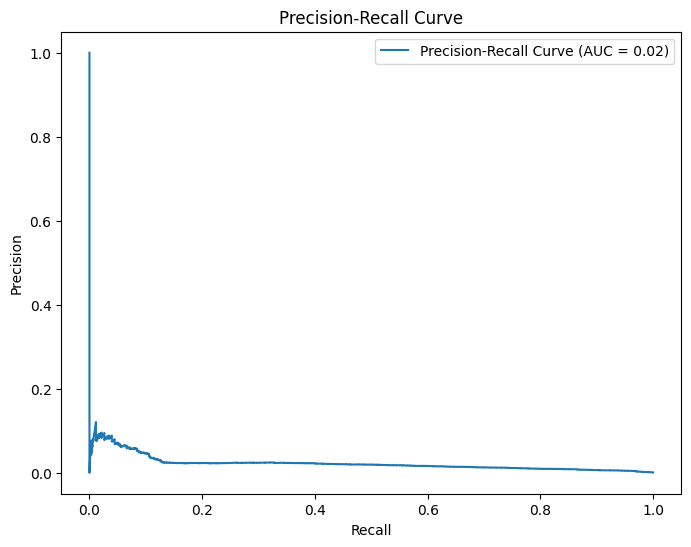

In [ ]:
plt.figure(figsize=(8, 6))
plt.plot(recall, precision, label=f'Precision-Recall Curve (AUC = {auc_score:.2f})')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.legend()
plt.show()

In [ ]:
# Find the threshold that gets you closest to a target precision
# (framed as: "how many false alerts is acceptable per true catch")
target_precision = 0.15  # start here, adjust based on what you find
idx = np.argmin(np.abs(precision - target_precision))
chosen_threshold = thresholds[idx]

print(f"At threshold {chosen_threshold:.4f}: precision={precision[idx]:.3f}, recall={recall[idx]:.3f}")

y_val_pred_tuned = (y_val_proba >= chosen_threshold).astype(int)
print(confusion_matrix(y_val, y_val_pred_tuned))

At threshold 0.9812: precision=0.121, recall=0.012
[[745678     51]
 [   598      7]]


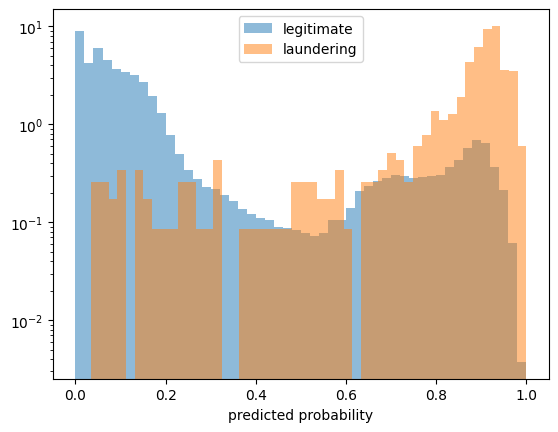

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Look at the actual score distributions, split by true class
plt.hist(y_val_proba[y_val == 0], bins=50, alpha=0.5, label='legitimate', density=True)
plt.hist(y_val_proba[y_val == 1], bins=50, alpha=0.5, label='laundering', density=True)
plt.legend(); plt.xlabel('predicted probability'); plt.yscale('log')

In [ ]:
print(f"Distinct probability values assigned to positives: {len(np.unique(y_val_proba[y_val==1]))}")
print(f"Positives above 0.5: {(y_val_proba[y_val==1] > 0.5).sum()} / {(y_val==1).sum()}")
print(f"Positives above 0.9: {(y_val_proba[y_val==1] > 0.9).sum()} / {(y_val==1).sum()}")

Distinct probability values assigned to positives: 605
Positives above 0.5: 562 / 605
Positives above 0.9: 338 / 605


Text(0, 0.5, 'Precision')

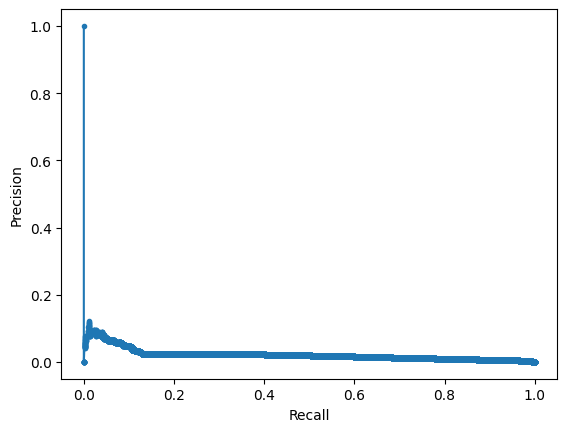

In [ ]:
plt.plot(recall, precision, marker='.')
plt.xlabel("Recall"); plt.ylabel("Precision")

In [ ]:
## Use Xgboost

from xgboost import XGBClassifier

x_model = XGBClassifier()

x_model.fit(X_train, y_train)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric=None, feature_types=None,
              feature_weights=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=None, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=None,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=None,
              n_jobs=None, num_parallel_tree=None, ...)

In [52]:
y_val_x_proba = x_model.predict_proba(X_val)[:, 1]

In [58]:
print(f"XGBoost PR-AUC (average precision): {average_precision_score(y_val, y_val_x_proba)}")

XGBoost PR-AUC (average precision): 0.04725622245415399


In [44]:
# Use grid search

from sklearn.model_selection import GridSearchCV

scale_pos_weight=(y_train==0).sum()/y_train.sum()
xgb = XGBClassifier(
    scale_pos_weight=scale_pos_weight,
    tree_method='hist',               # Fast histogram-based tree building
    random_state=42
)

# param_grid = {
#     'n_estimators': [100, 200, 300],
#     'learning_rate': [0.05, 0.1],
#     'max_depth': [3, 4, 5],
# }

# grid_search = GridSearchCV(xgb,
#                            param_grid,
#                            cv=5,
#                            scoring='average_precision',
#                            n_jobs=-1)

xgb.fit(X_train, y_train)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric=None, feature_types=None,
              feature_weights=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=None, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=None,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=None,
              n_jobs=None, num_parallel_tree=None, ...)

In [54]:
y_val_x_pred_1 = xgb.predict_proba(X_val)[:, 1]


In [55]:
print(f"████ XGBoost with Scale POS Weight PR-AUC (average precision): {average_precision_score(y_val, y_val_x_pred_1)}")

████ XGBoost with Scale POS Weight PR-AUC (average precision): 0.09565108430672989
